# Explore the Bundesbank German zero-coupon curve

Bundesbank Svensson zero-coupon curve for German federal securities, percent, daily (`load_curve("DE")`). Daily values start in 1997 (30Y in 2000), so the usable six-maturity sample starts 2000-08. Used as a longer-history robustness check.

Same exploration for each of the three datasets (`01_ecb_aaa`, `02_bundesbank_de`, `03_fed_us`).

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller, kpss
from scenario_lab.data import load_curve
plt.style.use("default"); plt.rcParams["figure.facecolor"] = "white"  # undo IDE dark-theme recolouring
warnings.filterwarnings("ignore")  # statsmodels API/table-range warnings; KPSS p is clipped to [0.01, 0.1]

d = load_curve("DE")
MATS = [1, 2, 5, 10, 20, 30]
print(d.shape, d.index.min().date(), d.index.max().date(), "NaN:", int(d.isna().sum().sum()))
d.describe().round(2)

(6684, 6) 2000-08-01 2026-11-20 NaN: 0


,1Y,2Y,5Y,10Y,20Y,30Y
count,6684.00,6684.00,6684.00,6684.00,6684.00,6684.00
mean,1.38,1.45,1.81,2.38,2.89,2.97
std,1.75,1.75,1.76,1.75,1.75,1.76
min,-0.97,-1.02,-0.98,-0.85,-0.62,-0.50
25%,-0.28,-0.26,-0.01,0.60,1.20,1.37
50%,1.12,1.50,2.17,2.54,2.94,2.84
75%,2.84,2.80,3.27,3.92,4.35,4.40
max,5.23,5.32,5.35,5.43,5.94,6.27


## 1. History of each maturity

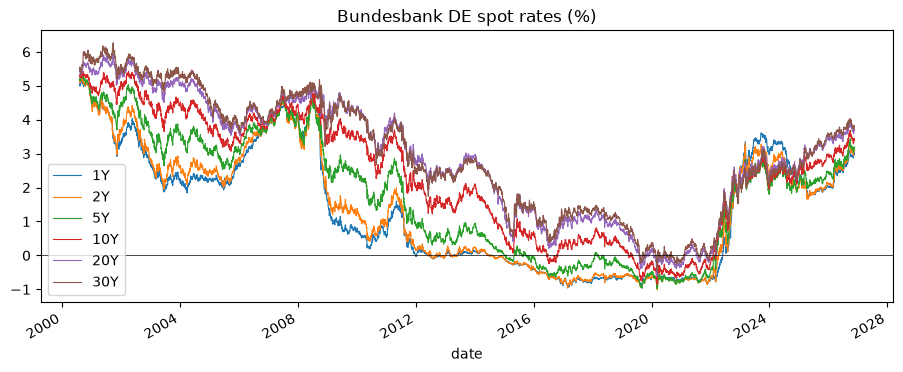

In [2]:
d.plot(figsize=(11, 4), lw=0.8, title="Bundesbank DE spot rates (%)"); plt.axhline(0, c="k", lw=0.5); plt.show()

## 2. Curve shapes on selected dates

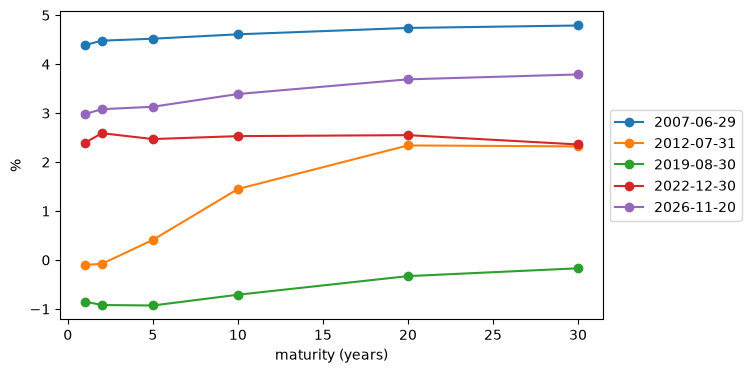

In [3]:
dates = ["2007-06-29", "2012-07-31", "2019-08-30", "2022-12-30", "2100-01-01"]      # last entry = latest available day
fig, ax = plt.subplots(figsize=(7, 4))
for dt in dates:
    r = d.loc[:dt].iloc[-1]
    ax.plot(MATS, r.values, marker="o", label=str(r.name.date()))
ax.set(xlabel="maturity (years)", ylabel="%"); ax.legend(loc="center left", bbox_to_anchor=(1, 0.5)); plt.show()

## 3. Rate changes (weekly, Friday-to-Friday) and cross-maturity correlation

In [4]:
w = d.resample("W-FRI").last()
dw = w.diff().dropna()
print(dw.describe().round(3).loc[["std", "min", "max"]])
print("excess kurtosis:\n", dw.kurt().round(2))
print(dw.corr().round(2))

        1Y     2Y    5Y    10Y   20Y    30Y
std  0.078  0.092  0.10  0.097  0.10  0.107
min -1.030 -0.580 -0.40 -0.380 -0.42 -0.590
max  0.420  0.400  0.44  0.450  0.44  0.490
excess kurtosis:
 1Y     25.87
2Y      4.11
5Y      1.66
10Y     1.02
20Y     1.52
30Y     1.86
dtype: float64
       1Y    2Y    5Y   10Y   20Y   30Y
1Y   1.00  0.91  0.72  0.56  0.41  0.38
2Y   0.91  1.00  0.90  0.72  0.54  0.50
5Y   0.72  0.90  1.00  0.91  0.74  0.68
10Y  0.56  0.72  0.91  1.00  0.91  0.83
20Y  0.41  0.54  0.74  0.91  1.00  0.94
30Y  0.38  0.50  0.68  0.83  0.94  1.00


## 4. Stationarity: levels vs weekly changes

ADF null: unit root. KPSS null: stationary. Read them together; ADF has low power on persistent series.

In [5]:
rows = []
for name, s in [("level", w), ("change", dw)]:
    for c in s.columns:
        rows.append((name, c, adfuller(s[c], autolag="AIC")[1], kpss(s[c], regression="c", nlags="auto")[1]))
res = pd.DataFrame(rows, columns=["series", "mat", "ADF p", "KPSS p"]).round(3)
res.pivot(index="mat", columns="series", values=["ADF p", "KPSS p"]).reindex([f"{m}Y" for m in MATS])

ADF p        KPSS p      
series change  level change level
mat                              
1Y        0.0  0.221  0.029  0.01
2Y        0.0  0.289  0.025  0.01
5Y        0.0  0.381  0.029  0.01
10Y       0.0  0.474  0.049  0.01
20Y       0.0  0.526  0.080  0.01
30Y       0.0  0.436  0.078  0.01

## 5. Volatility clustering: rolling 1-year std of weekly changes

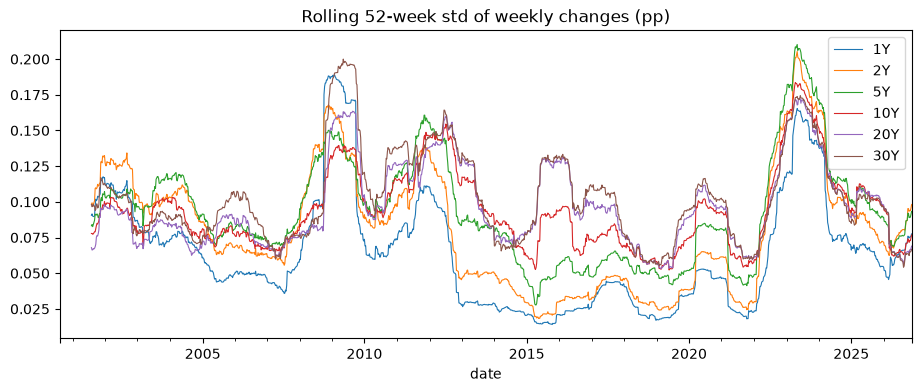

In [6]:
dw.rolling(52).std().plot(figsize=(11, 4), lw=0.8, title="Rolling 52-week std of weekly changes (pp)"); plt.show()

## 6. Relation to ECB AAA

Correlation of 10Y changes over different horizons, and a lead/lag check, on the days both curves are available. The two curves are snapshots taken at different times of day (the Bundesbank value earlier, the ECB value later), so daily changes are not synchronous.

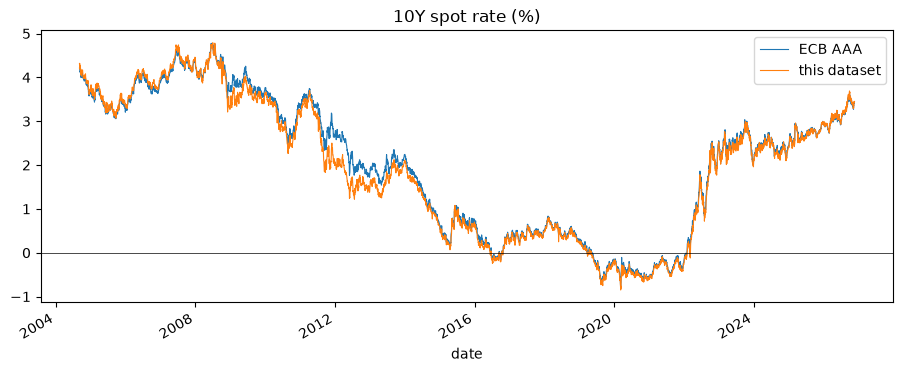

correlation of 10Y changes with ECB AAA, by horizon
1-day     0.58
5-day     0.89
20-day    0.95
60-day    0.97
dtype: float64
mean 10Y level gap (this dataset - AAA, pp): -0.09
corr(ECB AAA change on day t, this dataset change on day t+k)
-2   -0.00
-1   -0.01
0     0.58
1     0.38
2    -0.00
dtype: float64
lag-1 autocorrelation of daily changes: ECB AAA 0.025 | this dataset -0.028


In [7]:
aaa = load_curve("AAA")
c10 = pd.concat({"ECB AAA": aaa["10Y"], "this dataset": d["10Y"]}, axis=1, sort=True).dropna()
c10.plot(figsize=(11, 4), lw=0.8, title="10Y spot rate (%)"); plt.axhline(0, c="k", lw=0.5); plt.show()
print("correlation of 10Y changes with ECB AAA, by horizon")
print(pd.Series({f"{h}-day": c10.diff(h).dropna().corr().iloc[0, 1] for h in (1, 5, 20, 60)}).round(2))
print("mean 10Y level gap (this dataset - AAA, pp):", round((c10["this dataset"] - c10["ECB AAA"]).mean(), 2))
d1 = c10.diff().dropna()
a, b = d1["ECB AAA"], d1["this dataset"]
print("corr(ECB AAA change on day t, this dataset change on day t+k)")
print(pd.Series({k: a.corr(b.shift(-k)) for k in (-2, -1, 0, 1, 2)}).round(2))
print("lag-1 autocorrelation of daily changes: ECB AAA", round(a.autocorr(1), 3), "| this dataset", round(b.autocorr(1), 3))

## Observations

- **Sample:** 6,684 days from 2000-08 to 2026-11 (26.3 years), rates from -1.0% to 6.3%. About 8 holidays per year are missing, never more than 3 days in a row.
- **Weekly changes:** std 0.08 pp (1Y) to 0.11 pp (30Y). The 1Y excess kurtosis is 26, much higher than ECB AAA (11), then 1-4 at the other maturities.
- **Stationarity:** same pattern as ECB AAA: unit root not rejected in the levels (p 0.22-0.53), rejected for changes; KPSS rejects stationary levels.
- **Relation to ECB AAA:** the levels are close (10Y gap -0.09 pp). The series are snapshots at different times of day, so daily changes are not synchronous: the 10Y correlation is 0.58 on the same day and 0.38 between the ECB change on day t and the Bundesbank change on day t+1 (the Bundesbank value is taken earlier in the day). Neither series is shifted or stale (own lag-1 autocorrelation of daily changes is about 0: ECB +0.03, Bundesbank -0.03). The correlation rises to 0.89 over 5 days and 0.95 over 20 days, so weekly data are effectively aligned.